Mean-Covariance Practical Project

5 tasks

1. Data -> Download prices split 2024/2025, compute and plot returns
2. Estimation -> Choose flexible probabilities, compute the effective number of scenarios (ens)
estimate mean and covariance
3. Model -> Principal-component LFM: eigenvalue plot: r² vs number of factors: σ² and k̄
4. Evaluation -> Use the 2024 model to predict 2025 returns, plot predicted vs actual
5. Interpretation -> Read the first 2 eigenvectors as portfolios, plot their 2025 returns
explain them financially.

Objective:
Designed to give hands-on experience in building a principal component linear factor model (LFM) to understand and
capture the key drivers of a market of technology stocks.
I will use my model to identify underlying risk factors and construct diversified portfolios that
reflect these factors.

Background:
In vesting in individual technology stocks can be costly and leaves retail investors under-diversified.
One way to solve this is by creating factor portfolios that capture the main sources of co-movement in th sector.
In this project, I will build a principal component linear factor model (LFM) to construct such portfolios,
test their predictive performance, and interpret the economic meaning of the most important factors.

Market:
The market consists of 14 technology stocks plus one risk-free instrument.
The stocks are: AAPL, MSFT, GOOGL, AMZN, META, CSCO, NVDA, ORCL, PLTR, SAP, IBM, CRM, SHOP, UBER.

Data:
- Training data: Daily linear returns in 2024.
- Testing data: Daily linear returns from 1 Jan 2025 to 30 Sept 2025.
- Assumptions: Returns are stationary and ergodic;  I may fit a static LFM.
Portfolios with weights not summing to one are adjusted via the risk-free instrument.

Prepare the environment

In [21]:
# Imports cell
from yfinance import download
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Task 1: Data Preparation
The approach,
There are 3 jobs:

1. Download adjusted close prices for the 14 stocks from Jan 2024 to Sept 2025, using package yfinance
2. Turn prices into f=daily linear returns: R_t = P_t /P_{t-1}-1.
These are the target variables X that the model explains, the same as in s_pca_truncated_lfm.
3. Split into training (2024) and testing(2025) datasets.
Fit everything on 2024, then check whether it still works on 2025 data the model has never seen.
4. Compute and plot daily linear returns for each stock.

[*********************100%***********************]  13 of 14 completed


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Date,,,,,,,,,,,,,,
2024-01-02,183.403992,149.929993,251.332031,46.821121,136.867599,148.906357,343.004852,363.117920,48.028786,100.446449,16.58,144.507050,73.830002,58.380001
2024-01-03,182.030762,148.470001,247.122391,47.185448,137.610535,147.615524,341.202118,362.853577,47.431526,98.902000,16.09,144.102966,71.820000,58.250000
2024-01-04,179.718933,144.570007,246.533630,46.783760,135.104385,148.316254,343.826965,360.249207,47.859280,99.027481,16.25,142.881210,73.419998,57.799999
2024-01-05,178.997742,145.240005,246.415848,46.793091,134.450592,146.748856,348.611145,360.063171,48.955105,99.162628,15.98,144.160721,74.510002,57.580002
2024-01-08,183.324982,149.100006,255.983200,47.138741,137.531265,148.574448,355.257446,366.858063,52.101986,101.025620,16.67,146.767807,77.690002,59.009998


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Date,,,,,,,,,,,,,,
2025-09-24,251.381409,220.210007,243.821945,65.699623,246.498947,260.751282,758.088501,505.986908,176.547028,303.860046,179.559998,264.256256,148.830002,97.779999
2025-09-25,255.924606,218.149994,238.923492,66.216873,245.152451,274.308838,746.378174,502.892365,177.265305,286.985474,179.119995,258.024597,143.449997,97.599998
2025-09-26,254.519806,219.779999,241.382645,65.602036,245.900467,277.106110,741.235657,507.286194,177.764099,279.232880,177.570007,259.567749,140.250000,98.449997
2025-09-29,253.493591,222.169998,243.038574,66.090004,243.416962,272.710358,740.886841,510.400574,181.415375,278.543335,178.860001,259.312195,149.000000,99.570000
2025-09-30,253.692871,219.570007,235.006714,66.773140,242.469437,275.010620,731.897400,513.723267,186.134064,277.045959,182.419998,262.644257,148.610001,97.970001


Missing Adj Close prices per stock : 
Ticker
AAPL     0
AMZN     0
CRM      0
CSCO     0
GOOGL    0
IBM      0
META     0
MSFT     0
NVDA     0
ORCL     0
PLTR     0
SAP      0
SHOP     0
UBER     0


Training:  (251, 14) from 2024-01-03 to 2024-12-31


Testing:  (186, 14) from 2025-01-02 to 2025-09-30



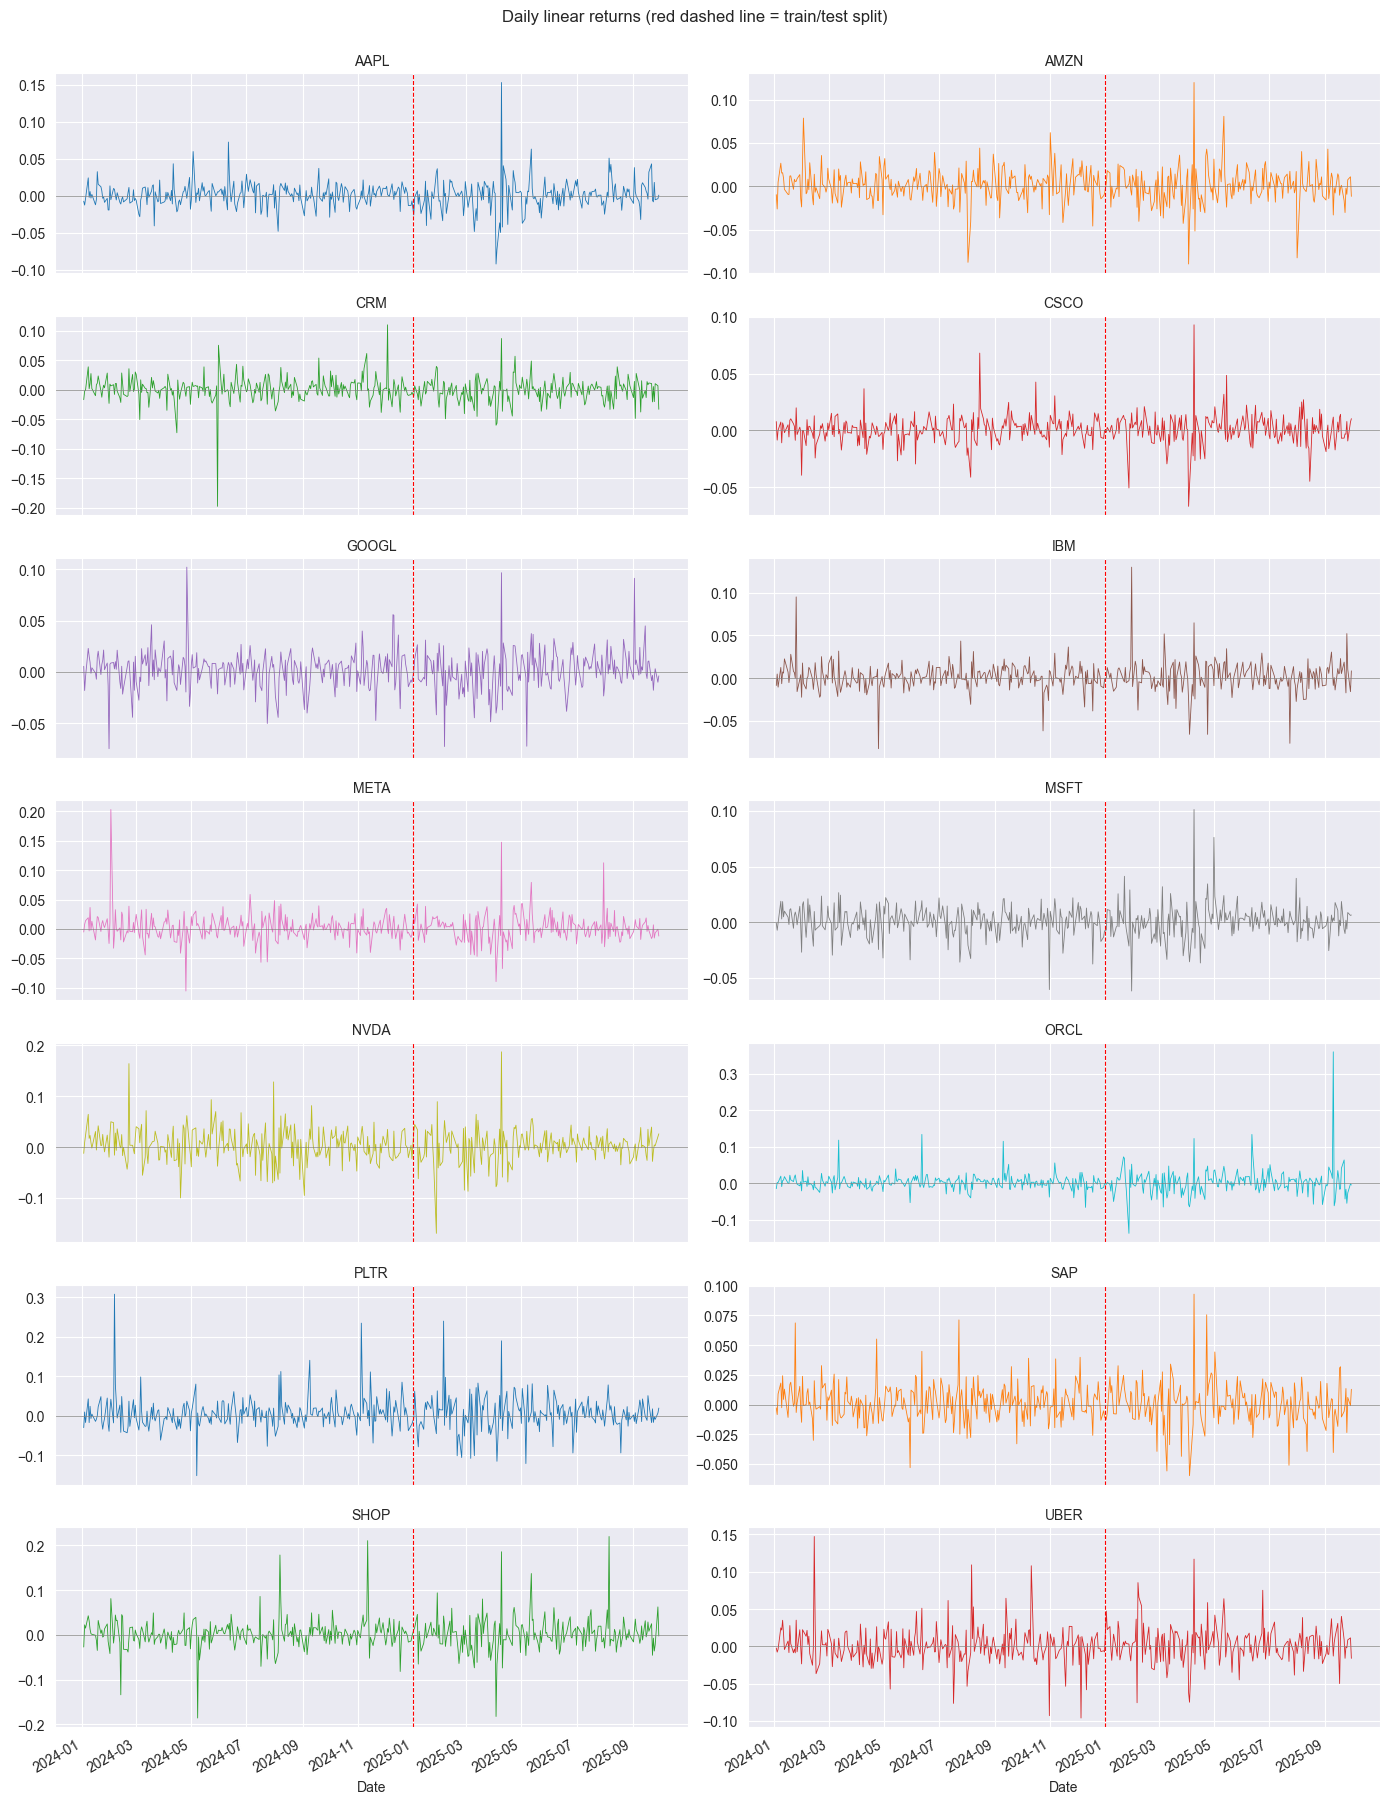

        mean daily return (%)  daily volatility (%)  worst day (%)  \
Ticker                                                               
PLTR                     0.68                  4.05         -15.11   
SHOP                     0.20                  3.32         -18.59   
NVDA                     0.46                  3.31         -10.00   
UBER                     0.04                  2.51          -9.60   
META                     0.24                  2.30         -10.56   
CRM                      0.13                  2.26         -19.74   
ORCL                     0.21                  2.03          -6.67   
AMZN                     0.17                  1.77          -8.78   
GOOGL                    0.14                  1.77          -7.50   
SAP                      0.21                  1.57          -5.32   
IBM                      0.15                  1.47          -8.25   
AAPL                     0.13                  1.41          -4.82   
MSFT                

In [22]:
# list of technology stock tickers
tickers = ['AAPL','MSFT', 'GOOGL', 'AMZN', 'META', 'CSCO', 'NVDA', 'ORCL', 'PLTR', 'SAP', 'IBM', 'CRM', 'SHOP', 'UBER']

# date range
start_date = "2024-01-01"
# changed end_date to include 30th September (as defined in the brief)
end_date = "2025-10-01"

# daily adjusted closing prices
# rows = trading days
# columns = stocks
data = download(tickers, start=start_date, end=end_date, auto_adjust=False)['Adj Close']
display(data.head())
display(data.tail())

# Check Adj Close prices for all stocks are complete
close_prices = data.dropna(how='all')
print('Missing Adj Close prices per stock : ')
print(close_prices.isna().sum().to_string())
print()

# Daily linear returns: todays_return = todays_price / yesterdays_price -1
# pct_change does this for every stock at once,
# The first row is Nan (due to no previous day) so we drop it here
# returns are calculated on the whole price history before splitting
daily_linear_returns = close_prices.pct_change().dropna()

# Splitting (after daily linear returns calc) into training dataset (2024) and testing dataset (2025)
training_returns = daily_linear_returns.loc['2024-01-01' : '2024-12-31']
testing_returns = daily_linear_returns.loc['2025-01-01' : '2025-09-30']

print('\nTraining: ', training_returns.shape, 'from',
      training_returns.index[0].date(), 'to', training_returns.index[-1].date())
print()
print('\nTesting: ', testing_returns.shape, 'from',
      testing_returns.index[0].date(), 'to', testing_returns.index[-1].date())
print()

# Plot daily returns, one panel per stock
axes = daily_linear_returns.plot(subplots=True, layout=(7,2), figsize=(14,18),
                                 sharex=True, legend=False, linewidth=0.6)

for ax, ticker in zip(axes.flatten(), daily_linear_returns.columns):
    ax.set_title(ticker, fontsize=10)
    ax.axvline(pd.Timestamp('2025-01-01'), color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='grey', linewidth=0.5)

plt.suptitle('Daily linear returns (red dashed line = train/test split)', y=1.0)
plt.tight_layout()
plt.show()

# Summary of the training data
training_summary = pd.DataFrame({
    'mean daily return (%)': 100 * training_returns.mean(),
    'daily volatility (%)': 100 * training_returns.std(),
    'worst day (%)': 100 * training_returns.min(),
    'best day (%)': 100 * training_returns.max(),
}).round(2)
print(training_summary.sort_values('daily volatility (%)', ascending=False))


# Task 2: Estimation

- Choose and justify a set of flexible probabilities for the training data.
- Compute the effective number of scenarios.
- Estimate the mean and covariance of training returns.  Explain and defend my chosen estimations method.

Probabilities sum to:  1.0
Newest day weight / oldest day weight:  3.96

effective_number_of_scenarios with 126-day half-life: 232.7 out of 251 days
effective_number_of_scenarios with equal weights:    251.0



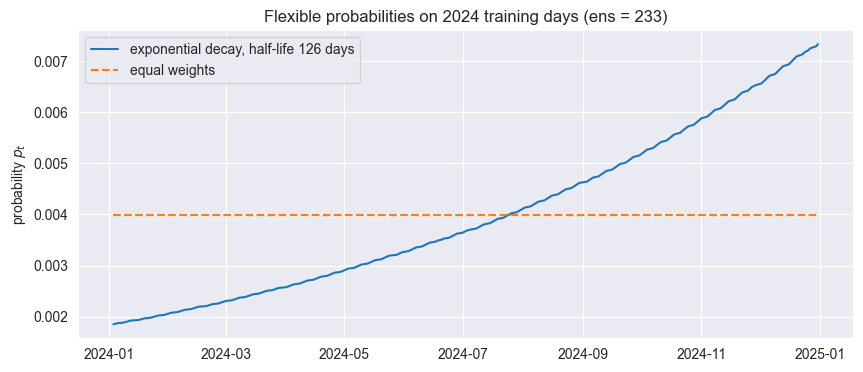

In [23]:
# Flexible probabilities: Exponential decay
# 251 days x 14 stocks, one row per day
returns_matrix = training_returns.to_numpy()
# t_bar, n_bar
number_of_days, number_of_stocks = returns_matrix.shape

# tau_HL: ~ 6 months of trading days
half_life_days = 126

# label each day by how far it is from 31 Dec 2024
# How many days before the last training day each row is: 250, 249, ....,1, 0
days_before_last = np.arange(number_of_days)[::-1]

# giving each day a weight, that will halve every 126 days
# w_t = exp(-(ln2 / tau_HL) * distance), then normalise so the weights sum to 1
decay_weights = np.exp(-np.log(2) / half_life_days * days_before_last)

# rescale the weights so they add up to 1 (turns them into probabilities)
flexible_probabilities = decay_weights / decay_weights.sum()

# Benchmark: equal weights p_t = 1 / t_bar
equal_probabilities = np.full(number_of_days, 1 / number_of_days)

# Confirming the probabilities
print('Probabilities sum to: ', flexible_probabilities.sum().round(6))
print('Newest day weight / oldest day weight: ', (flexible_probabilities[-1] / flexible_probabilities[0]).round(2))
print()

# Effective number of scenarios: ens = exp(-sum p ln p)
def effective_number_of_scenarios(probabilities):
    # Entropy based 'ens' : how many equally weighted days the weights are worth
    return np.exp(-probabilities @ np.log(probabilities))

effect_num_scenarios_decay = effective_number_of_scenarios(flexible_probabilities)
effect_num_scenarios_equal = effective_number_of_scenarios(equal_probabilities)
print(f'effective_number_of_scenarios with {half_life_days}-day half-life: {effect_num_scenarios_decay:.1f} out of {number_of_days} days')
print(f'effective_number_of_scenarios with equal weights:    {effect_num_scenarios_equal:.1f}')
print()

# Plotting the weights
plt.figure(figsize=(10, 4))
plt.plot(training_returns.index, flexible_probabilities, label=f'exponential decay, half-life {half_life_days} days')
plt.plot(training_returns.index, equal_probabilities, linestyle='--', label='equal weights')
plt.ylabel('probability $p_t$')
plt.title(f'Flexible probabilities on 2024 training days (ens = {effect_num_scenarios_decay:.0f})')
plt.legend()
plt.show()
print()

In [24]:
# HFP mean and covariance
def hfp_mean_and_covariance(returns, probabilities):
    """
    Historical-with-flexible-probabilities estimators
    returns: (t_bar X n_bar) array, one row per day.
    Probabilities: (t_bar,) weights summing to 1
    """
    # multiply 251 weights by 251 returns and add up separately
    mean = probabilities @ returns
    # each days return minus that stocks mean
    deviations = returns - mean
    # weighted sum of (deviation x deviation) for every pair of stocks
    covariance = (deviations * probabilities[:, None]).T @ deviations
    return mean, covariance

# Main estimate: exponential-decay probabilities
mean_hfp, covariance_hfp = hfp_mean_and_covariance(returns_matrix, flexible_probabilities)

# Benchmark: equal weights
mean_equal, covariance_equal = hfp_mean_and_covariance(returns_matrix, equal_probabilities)

# Wrapping labelled DataFrames so the stock names stay attached
stock_names = training_returns.columns
mean_hfp = pd.Series(mean_hfp, index=stock_names)
covariance_hfp = pd.DataFrame(covariance_hfp, index=stock_names, columns=stock_names)

# Volatilities and correlation implied by the HFP covariance
volatility_hfp = np.sqrt(np.diag(covariance_hfp))
correlation_hfp = covariance_hfp / np.outer(volatility_hfp, volatility_hfp)

print('HFP mean daily return (%): ')
display((100 * mean_hfp).round(3).to_frame('mean (%)').T)
print()
print('HFP covariance (x 10^4, i.e. in %^2):')
display((1e4 * covariance_hfp).round(2))
print()
print('HFP correlation:')
display(correlation_hfp.round(2))

HFP mean daily return (%): 


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
mean (%),0.151,0.168,0.163,0.12,0.144,0.134,0.178,0.033,0.33,0.177,0.776,0.188,0.281,-0.047



HFP covariance (x 10^4, i.e. in %^2):


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Ticker,,,,,,,,,,,,,,
AAPL,1.86,0.86,0.46,0.27,0.85,0.26,0.80,0.86,1.20,0.66,1.18,0.74,1.15,0.49
AMZN,0.86,3.25,1.53,0.77,1.76,0.65,2.12,1.58,2.43,1.56,2.22,1.05,2.79,1.10
CRM,0.46,1.53,5.10,0.90,1.19,0.95,1.24,1.15,2.33,1.72,1.64,1.61,2.32,1.20
CSCO,0.27,0.77,0.90,1.29,0.47,0.61,0.28,0.46,0.64,0.61,1.10,0.36,0.99,0.51
GOOGL,0.85,1.76,1.19,0.47,3.14,0.21,1.62,1.24,1.80,0.80,1.03,0.73,1.71,0.48
IBM,0.26,0.65,0.95,0.61,0.21,2.04,0.70,0.50,0.79,0.90,1.12,0.59,0.98,0.47
META,0.80,2.12,1.24,0.28,1.62,0.70,4.31,1.55,2.59,1.23,2.28,1.24,2.18,1.27
MSFT,0.86,1.58,1.15,0.46,1.24,0.50,1.55,1.61,1.83,1.39,1.54,0.97,1.57,0.85
NVDA,1.20,2.43,2.33,0.64,1.80,0.79,2.59,1.83,10.19,2.80,3.58,2.06,2.57,2.08



HFP correlation:


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Ticker,,,,,,,,,,,,,,
AAPL,1.00,0.35,0.15,0.17,0.35,0.13,0.28,0.50,0.28,0.24,0.22,0.36,0.25,0.14
AMZN,0.35,1.00,0.38,0.38,0.55,0.25,0.56,0.69,0.42,0.42,0.31,0.38,0.46,0.24
CRM,0.15,0.38,1.00,0.35,0.30,0.30,0.26,0.40,0.32,0.37,0.18,0.46,0.31,0.21
CSCO,0.17,0.38,0.35,1.00,0.24,0.38,0.12,0.32,0.18,0.26,0.24,0.21,0.26,0.18
GOOGL,0.35,0.55,0.30,0.24,1.00,0.08,0.44,0.55,0.32,0.22,0.15,0.27,0.29,0.11
IBM,0.13,0.25,0.30,0.38,0.08,1.00,0.24,0.28,0.17,0.31,0.20,0.27,0.20,0.13
META,0.28,0.56,0.26,0.12,0.44,0.24,1.00,0.59,0.39,0.29,0.28,0.39,0.31,0.24
MSFT,0.50,0.69,0.40,0.32,0.55,0.28,0.59,1.00,0.45,0.54,0.30,0.50,0.37,0.26
NVDA,0.28,0.42,0.32,0.18,0.32,0.17,0.39,0.45,1.00,0.43,0.28,0.42,0.24,0.26


In [25]:
# Sanity checks - also decay vs equal comparison

# Equal-weight HFP must equal numpy's sample covariance
print('Equal-weight HFP matches np.cov(bias=True):  ',
      np.allclose(covariance_equal, np.cov(returns_matrix.T, bias=True)))
print()

# A valid covariance is symmetric with all eigenvalues > 0
eigenvalues_check = np.linalg.eigvalsh(covariance_hfp)
print('Symmetric: ', np.allclose(covariance_hfp, covariance_hfp.T),
      '| smallest eigenvalue > 0: ', eigenvalues_check.min() > 0)
print()

# How precisely is each mean estimated? standard error ~ volatility / sqrt(ens)
estimate_comparison = pd.DataFrame({
    'mean, decay (%)': 100 * mean_hfp,
    'mean, equal (%)': 100 * mean_equal,
    'std error of mean (%)': 100 * volatility_hfp / np.sqrt(effect_num_scenarios_decay),
    'vol, decay (%)': 100 * volatility_hfp,
    'vol, equal (%)': 100 * np.sqrt(np.diag(covariance_equal)),
}, index=stock_names).round(3)
display(estimate_comparison)

# How different is the covariance under the 2 weighting schemes? (relative Frobenius distance)
relative_difference = np.linalg.norm(covariance_hfp.to_numpy() - covariance_equal) / np.linalg.norm(covariance_equal)
print(f'Covariance: decay vs equal weights differ by {100 * relative_difference:.1f}%')
print()

# Average pairwise correlation: a first hint of how strong the tech market factor is
average_correlation = correlation_hfp.to_numpy()[np.triu_indices(number_of_stocks, 1)].mean()
print(f'Average Pairwise Correlation: {average_correlation:.2f}')

Equal-weight HFP matches np.cov(bias=True):   True

Symmetric:  True | smallest eigenvalue > 0:  True



,"mean, decay (%)","mean, equal (%)",std error of mean (%),"vol, decay (%)","vol, equal (%)"
Ticker,,,,,
AAPL,0.151,0.131,0.089,1.362,1.409
AMZN,0.168,0.167,0.118,1.803,1.767
CRM,0.163,0.135,0.148,2.259,2.257
CSCO,0.120,0.082,0.074,1.134,1.135
GOOGL,0.144,0.142,0.116,1.772,1.765
IBM,0.134,0.148,0.094,1.429,1.471
META,0.178,0.237,0.136,2.077,2.293
MSFT,0.033,0.062,0.083,1.267,1.254
NVDA,0.330,0.463,0.209,3.192,3.301


Covariance: decay vs equal weights differ by 6.3%

Average Pairwise Correlation: 0.30


Data choices (Task 1):

Prices are adjusted prices for splits and dividends, so returns are total returns.

Returns were computed on the full price series before splitting, which keeps the 2nd of Jan 2025 return value.

This is not leakage: a linear return series uses only the current and previous day's prices and estimates
nothing from the data.
All estimates below use 2024 data only.

Flexible probabilities (what I chose and why):

I gave recent days more weight than older days using exponential decay with a half-life of 126 trading
days (approx 6 months).
This means a day's weight halves for every 6 months you go back.
The last day of 2024 counts about 4 x as much as the first day.

Why not equal weights?

The Equal Weights approach treats January 2024 as just as relevant as December 2024.

The model will be used on 2025, so I wanted the most recent behaviour to count a bit more.

Why not a shorter half-life?

There is only 1 year of data,  a short half-life (1 month) would throw most of what i feel is relevant away, 6 months gives a
sensible tilt without throwing away to much.


Effective number of scenarios:

effective_number_of_scenarios = 232.7 of 251 days,
In other words, my weighting is worth about 233 equally weighted days,  so i keep approx 93% of
the information in the data, the tilt towards recent days costs very little

How reliable are the estimates?

The covariance is reliable.  Switching between decay and equal weights changes it by only 6.3%,
and most stock's volatilities change by less than 0.05% (with exceptions for META and NVDA),
the weighting choice doesnt change the picture.
The largest change is META, whose +20% day (early in 2024) gets less weight under decay.
The 'means' are much less reliable.

Their uncertainty (standard error) is about as big as the means themselves:
Only PLTR (0.78% a day) is clearly above zero.
As can be seen MSFT and UBER are indistinguishable from zero, and UBERs mean even changes sign between
the 2 weightings.

Possible improvements:

A robust estimate that down-weights extreme days, such as a Student-t (MLFP) fit,
and shrinking the noisy mean towards a common value.

# Task 3: Model Building

- Build a principal component LFM on the training data.
- Plot the eigenvalues of the rescaled covariance matrix from largest to smallest.
- Compute the r-squared for each number of included factors and plot r-squared vs factor count.
- Discuss your choices of scaling matrix and number of factors.

In [26]:
# scaling matrix: sigma = Diag(volatilities)
# sigma
scale_matrix = np.diag(volatility_hfp)
# inverse sigma
inverse_scale_matrix = np.diag(1 / volatility_hfp)

# Rescaled covariance: sigma^-1 * covariance * sigma^-1 (= the HFP correlation matrix)
rescaled_covariance = inverse_scale_matrix @ covariance_hfp.to_numpy() @ inverse_scale_matrix

# Eigen decomposition
# eigh returns ascending order
eigenvalues, eigenvectors = np.linalg.eigh(rescaled_covariance)
# largest eigenvalue first
eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]

# Sign convention: make the largest entry (by size) of each eigenvector +ve
row_of_largest_entry = np.argmax(np.abs(eigenvectors), axis=0)
columns_to_flip = eigenvectors[row_of_largest_entry, np.arange(number_of_stocks)] < 0
eigenvectors[:, columns_to_flip] = -eigenvectors[:, columns_to_flip]

# r_squared for k = 1,2,3...,14 factors
r_squared_by_number_factors = np.cumsum(eigenvalues) / np.sum(eigenvalues)

# Noise edge (Marchenko-Pastur upper edge)
# q = n_bar / effective_number_of_scenarios
dimension_ratio = number_of_stocks / effect_num_scenarios_decay
# assumes noise variance 1
noise_edge = (1 + np.sqrt(dimension_ratio)) ** 2
# variance left after factor 1
noise_variance_adjusted = eigenvalues[1:].mean()
noise_edge_adjusted = noise_variance_adjusted * (1 + np.sqrt(dimension_ratio)) ** 2

print('Eigenvalues add up to ', eigenvalues.sum().round(4), '(= number of stocks, as expected for a correlation matrix)')
print()
print(f'Noise edge: {noise_edge:.2f} (basic) | {noise_edge_adjusted:.2f} (adjusted for factor 1)')
print()

eigen_table = pd.DataFrame({
    'eigenvalue': eigenvalues,
    'share of variance (%)': 100 * eigenvalues / eigenvalues.sum(),
    'cumulative r-squared (%)': 100 * r_squared_by_number_factors,
    'above basic noise edge': eigenvalues > noise_edge,
    'above adjusted noise edge': eigenvalues > noise_edge_adjusted,
}, index=pd.Index(range(1, number_of_stocks + 1),  name='factor k')).round(2)
display(eigen_table)

Eigenvalues add up to  14.0 (= number of stocks, as expected for a correlation matrix)

Noise edge: 1.55 (basic) | 1.06 (adjusted for factor 1)



,eigenvalue,share of variance (%),cumulative r-squared (%),above basic noise edge,above adjusted noise edge
factor k,,,,,
1,5.13,36.62,36.62,True,True
2,1.26,9.02,45.64,False,True
3,1.03,7.38,53.02,False,False
4,1.01,7.21,60.23,False,False
5,0.84,6.01,66.23,False,False
6,0.77,5.50,71.74,False,False
7,0.72,5.11,76.85,False,False
8,0.64,4.57,81.42,False,False
9,0.64,4.54,85.95,False,False


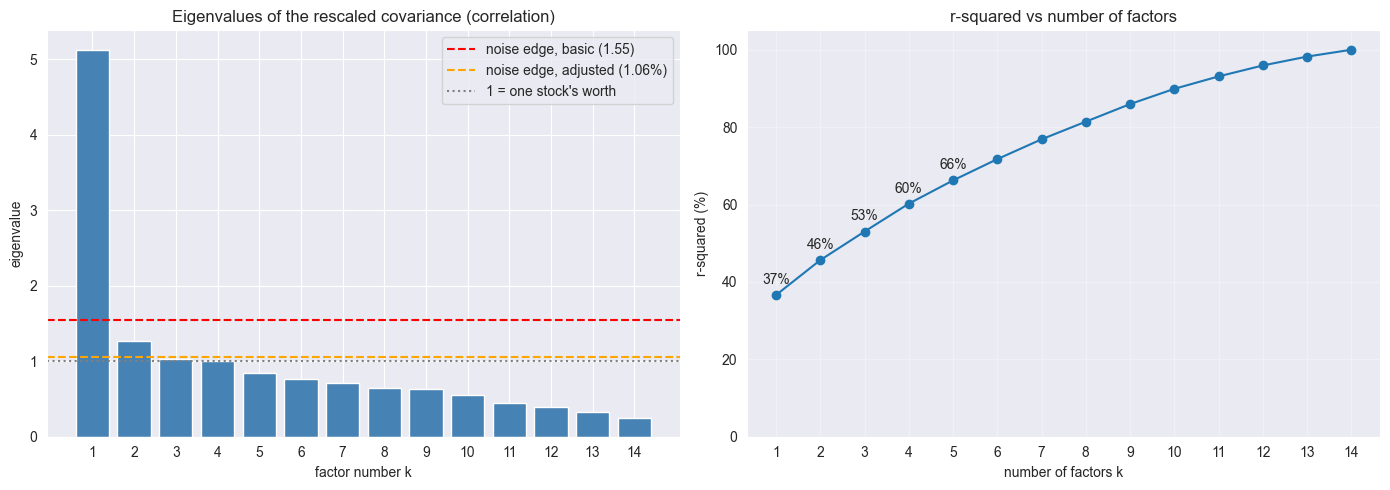

In [27]:
# Plots

factor_numbers = np.arange(1, number_of_stocks + 1)

fig, (ax_eig, ax_r2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: eigenvalues of the rescaled covariance, largest to smallest
ax_eig.bar(factor_numbers, eigenvalues, color='steelblue')
ax_eig.axhline(noise_edge, color='red', linestyle='--', label=f'noise edge, basic ({noise_edge:.2f})')
ax_eig.axhline(noise_edge_adjusted, color='orange', linestyle='--', label=f'noise edge, adjusted ({noise_edge_adjusted:.2f}%)')
ax_eig.axhline(1, color='grey', linestyle=':', label='1 = one stock\'s worth')
ax_eig.set(xlabel='factor number k', ylabel='eigenvalue', xticks=factor_numbers,
           title='Eigenvalues of the rescaled covariance (correlation)')
ax_eig.legend()

# Plot 2: r-squared vs number of factors
ax_r2.plot(factor_numbers, 100 * r_squared_by_number_factors, marker='o')
for k, r2 in zip(factor_numbers[:5], r_squared_by_number_factors[:5]):
    ax_r2.annotate(f'{100 * r2:.0f}%', (k, 100 * r2), textcoords='offset points', xytext=(0,8), ha='center')

ax_r2.set(xlabel='number of factors k', ylabel='r-squared (%)', xticks=factor_numbers,
          ylim=(0, 105), title='r-squared vs number of factors')
ax_r2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Building the model with my chose k_bar

# This has been set after looking at the plots above
number_of_factors = 2

# Loadings beta = sigma * e_(1:k): how much each stock moves per unit of each factor
# 14 x k
factor_loadings = scale_matrix @ eigenvectors[:, :number_of_factors]

# construction matrix gamma = e_(1:k)' * sigma^-1: recipe to build factors from the returns
#  k x 14
factor_construction_matrix = eigenvectors[:, :number_of_factors].T @ inverse_scale_matrix

# Intercepts alpha = HFP mean
intercepts = mean_hfp.to_numpy()

# Factor returns on each training day: z_t = gamma (x_t - m)
factor_returns_train = (returns_matrix - intercepts) @ factor_construction_matrix.T

# Model's fitted returns and the leftover residuals
fitted_returns_train = intercepts + factor_returns_train @ factor_loadings.T
residual_returns_train = returns_matrix - fitted_returns_train

# Checks: does the model behave as the theory says?
# 1 - gamma * beta = identity (compress then expand gives the factor back)
print('gamma @ beta = identity: ', np.allclose(factor_construction_matrix @ factor_loadings, np.eye(number_of_factors)))
print()

# 2 - Factors are uncorrelated, with variances = the eigenvalues using the same HFP weights
factor_mean = flexible_probabilities @ factor_returns_train
factor_deviations = factor_returns_train - factor_mean
factor_covariance = (factor_deviations * flexible_probabilities[:, None]).T @ factor_deviations
print('Factor covariance: \n', factor_covariance.round(4))
print('First eigenvalues: \n', eigenvalues[:number_of_factors].round(4))
print()

# Loadings table
factor_labels = [f'factor {i + 1}' for i in range(number_of_factors)]
loadings_table = pd.DataFrame(factor_loadings, index=stock_names, columns=factor_labels)
print('\nFactor loadings beta (return per unit of factor):')
display(loadings_table.round(4))

gamma @ beta = identity:  True

Factor covariance: 
 [[ 5.127  -0.    ]
 [-0.      1.2631]]
First eigenvalues: 
 [5.127  1.2631]


Factor loadings beta (return per unit of factor):


,factor 1,factor 2
Ticker,,
AAPL,0.0032,-0.0039
AMZN,0.0063,-0.0029
CRM,0.0059,0.0063
CSCO,0.0024,0.0049
GOOGL,0.0047,-0.0072
IBM,0.0028,0.0072
META,0.0061,-0.0058
MSFT,0.0047,-0.0024
NVDA,0.0088,-0.0023


Explain Task 3:
using my numbers above in Task 3 above.

Scaling matrix: what I chose and why
- I used sigma = Diag(volatilities): each stock's returns are divided by its own volatility before running PCA.
The "rescaled covariance" is then simply the correlation matrix.
- Why: the stocks have very different volatilities.   PLTR's variance is about 12xCSCO's.
Without rescaling, PCA would mostly pick up "the stocks that move the most" (PLTR, SHOP, NVDA)
rather than what the stocks have in common.
- Rescaling puts every stock on an equal footing, so the factors reflect shared movement, not just size of movement.
This is the natural scatter choice as defined in 26.b.1.6 Natural scatter specification.
- Check: the 14 eigenvalues add up to exactly 14, as they would for a correlation matrix.

Number of factors: what I chose and why
- I chose k_bar = 2 factors
- Factor 1 is clearly real.  Its eigenvalue is 5.13 and it carries about as much variance as 5 stocks on their own,
and this explains about 36% of the total variance by itself.
All 14 factors load +ve'ly on it, so its a "whole tech sector" factor.
- Factor 2 is borderline but worth keeping.  Its eigenvalues are close to (1.03, 1.01, 0.84,..), which is what random data with no real structure would produce.  Each adds only 5-7%

My approach to separating real factors from noise
- Even if the 14 stocks were completely unrelated, a sample from one year would still show some eigenvalues above 1, just by chance.
The noise edge (as defined in Unit 2) estimates how high those chance eigenvalues can go:
- Basic edge = 1.55.  Only 1 factor is above it.
- Adjusted edge = 1.06.  This corrects for factor 1 already soaking up a lot of the variance,
which leaves less for noise.  Factors 1 and 2 are above it, factor 3 (1.03) is not.
- So the data supports one strong factor, plus a second that is likely real.
Beyond that extra factors would most likely be fitting noise.

What the r-squared curve shows
- 2 factors explain 45.6% of he variance.  Reaching 90% would need about 10 factors, and 95% would need 12.
- This is very different from the yield curve, where 3 factors explained 95%.  Tech stocks share 1 common driver but also
have a lot of company specific movement (earnings, news).  Their average correlation is only 0.30, compared with the yield changes,
which are almost perfectly correlated.
- So the model is not meant to explain evey stock's daily moves.  It captures the main shared drivers, and a lower r2 is
expected for individual stocks.

Checks that the model is built correctly
- y x B = identity:  building the factors from the returns and then mapping them back works as expected.
- the 2 factors are uncorrelated, and their variances equal the eigenvalues, exactly as the theory says

# Task 4:
- Use your Model to predict returns for the 2025 test set.
- Plot predicted vs actual returns for each stock.
- Comment on performance: how well do the factor portfolios track realized returns?

In [29]:
# Predict 2025 returns with the frozen 2024 model

# safety check:  The 2025 columns must be in the same stock order as 2024
assert list(testing_returns.columns) == list(stock_names), 'Column order differs between training and testing! '

# 2025 actual returns: (186 days x 14 stocks)
actual_returns_test = testing_returns.to_numpy()

# 1. Build each day's 2 factor return with the 2024 recipe z_t = gamma (x_t - m)
# 186 x 2
factor_returns_test = (actual_returns_test - intercepts) @ factor_construction_matrix.T

# 2. Rebuild each stock's return from just these 2 factors: predicted x_t = m + beta z_t
# 186 x 14
predicted_returns_test = intercepts + factor_returns_test @ factor_loadings.T

# what the 2 factors could not explain
residual_returns_test = actual_returns_test - predicted_returns_test

# Labelled versions for plotting
predicted_test = pd.DataFrame(predicted_returns_test, index=testing_returns.index, columns=stock_names)

print('Predicted returns shape: ', predicted_test.shape, '(should match testing_returns: ', testing_returns.shape, ')')

Predicted returns shape:  (186, 14) (should match testing_returns:  (186, 14) )


In [30]:
# How well does it perform?

def r_squared_per_stock(actual, residual, probabilities=None):
    """
    Share of each stock's variance explained by the model: 1 - Var(residual) / Var(actual)
    Uses the given probabilities (HFP); equal weights if noe are given.
    """
    if probabilities is None:
        probabilities = np.full(actual.shape[0], 1 / actual.shape[0])

    def weighted_variance(values):
        # subtract each stock's weighted mean
        centred = values - probabilities @ values
        # weighted stock squared deviation, per stock
        return probabilities @ centred**2

    return 1 - weighted_variance(residual) / weighted_variance(actual)

# Per stock r-squared: 2024 with the same HFP weights as the model, 2025 with equal weight
r_squared_train = r_squared_per_stock(returns_matrix, residual_returns_train, flexible_probabilities)
r_squared_test = r_squared_per_stock(actual_returns_test, residual_returns_test)

# Does the prediction move with the actual return, day by day?
correlation_test = [np.corrcoef(actual_returns_test[:, n], predicted_returns_test[:, n])[0, 1]
                    for n in range(number_of_stocks)]

performance_table = pd.DataFrame({
    'r-squared 2024 (train, %)': 100 * r_squared_train,
    'r-squared 2025 (test, %)': 100 * r_squared_test,
    'correlation predicted vs actual (2025)': correlation_test,
    'average prediction error (% per day)': 100 * residual_returns_test.mean(axis=0)
}, index=stock_names).round(2)
display(performance_table.sort_values('r-squared 2025 (test, %)', ascending=False))

# Total r-squared across all stocks, on the same rescaled (correlation) basis as Task
def total_rescaled_r_squared(actual, residual, probabilities=None):
    """1 - total residual variance / total variance after dividing each stock by its 2024 volatility"""
    rescaled_actual = actual @ inverse_scale_matrix
    rescaled_residual = residual @ inverse_scale_matrix
    return 1 - np.trace(np.cov(rescaled_residual.T, bias=True)) / np.trace(np.cov(rescaled_actual.T, bias=True))

print(f'Total r-squared 2024 (from Task 3) : {100 * r_squared_by_number_factors[number_of_factors - 1]:.1f}%')
print()
print(f'Total r-squared 2025 (out of sample) : {100 * total_rescaled_r_squared(actual_returns_test, residual_returns_test):.1f}%')


,"r-squared 2024 (train, %)","r-squared 2025 (test, %)",correlation predicted vs actual (2025),average prediction error (% per day)
Ticker,,,,
AMZN,66.14,73.42,0.86,-0.11
META,54.45,68.39,0.83,0.02
MSFT,74.90,66.42,0.83,0.12
CSCO,47.05,62.10,0.80,-0.01
SHOP,30.97,61.16,0.79,0.02
NVDA,39.87,60.93,0.78,-0.05
GOOGL,57.26,56.92,0.76,0.05
IBM,51.67,53.53,0.74,0.04
AAPL,38.47,49.72,0.75,-0.09


Total r-squared 2024 (from Task 3) : 45.6%

Total r-squared 2025 (out of sample) : 51.6%


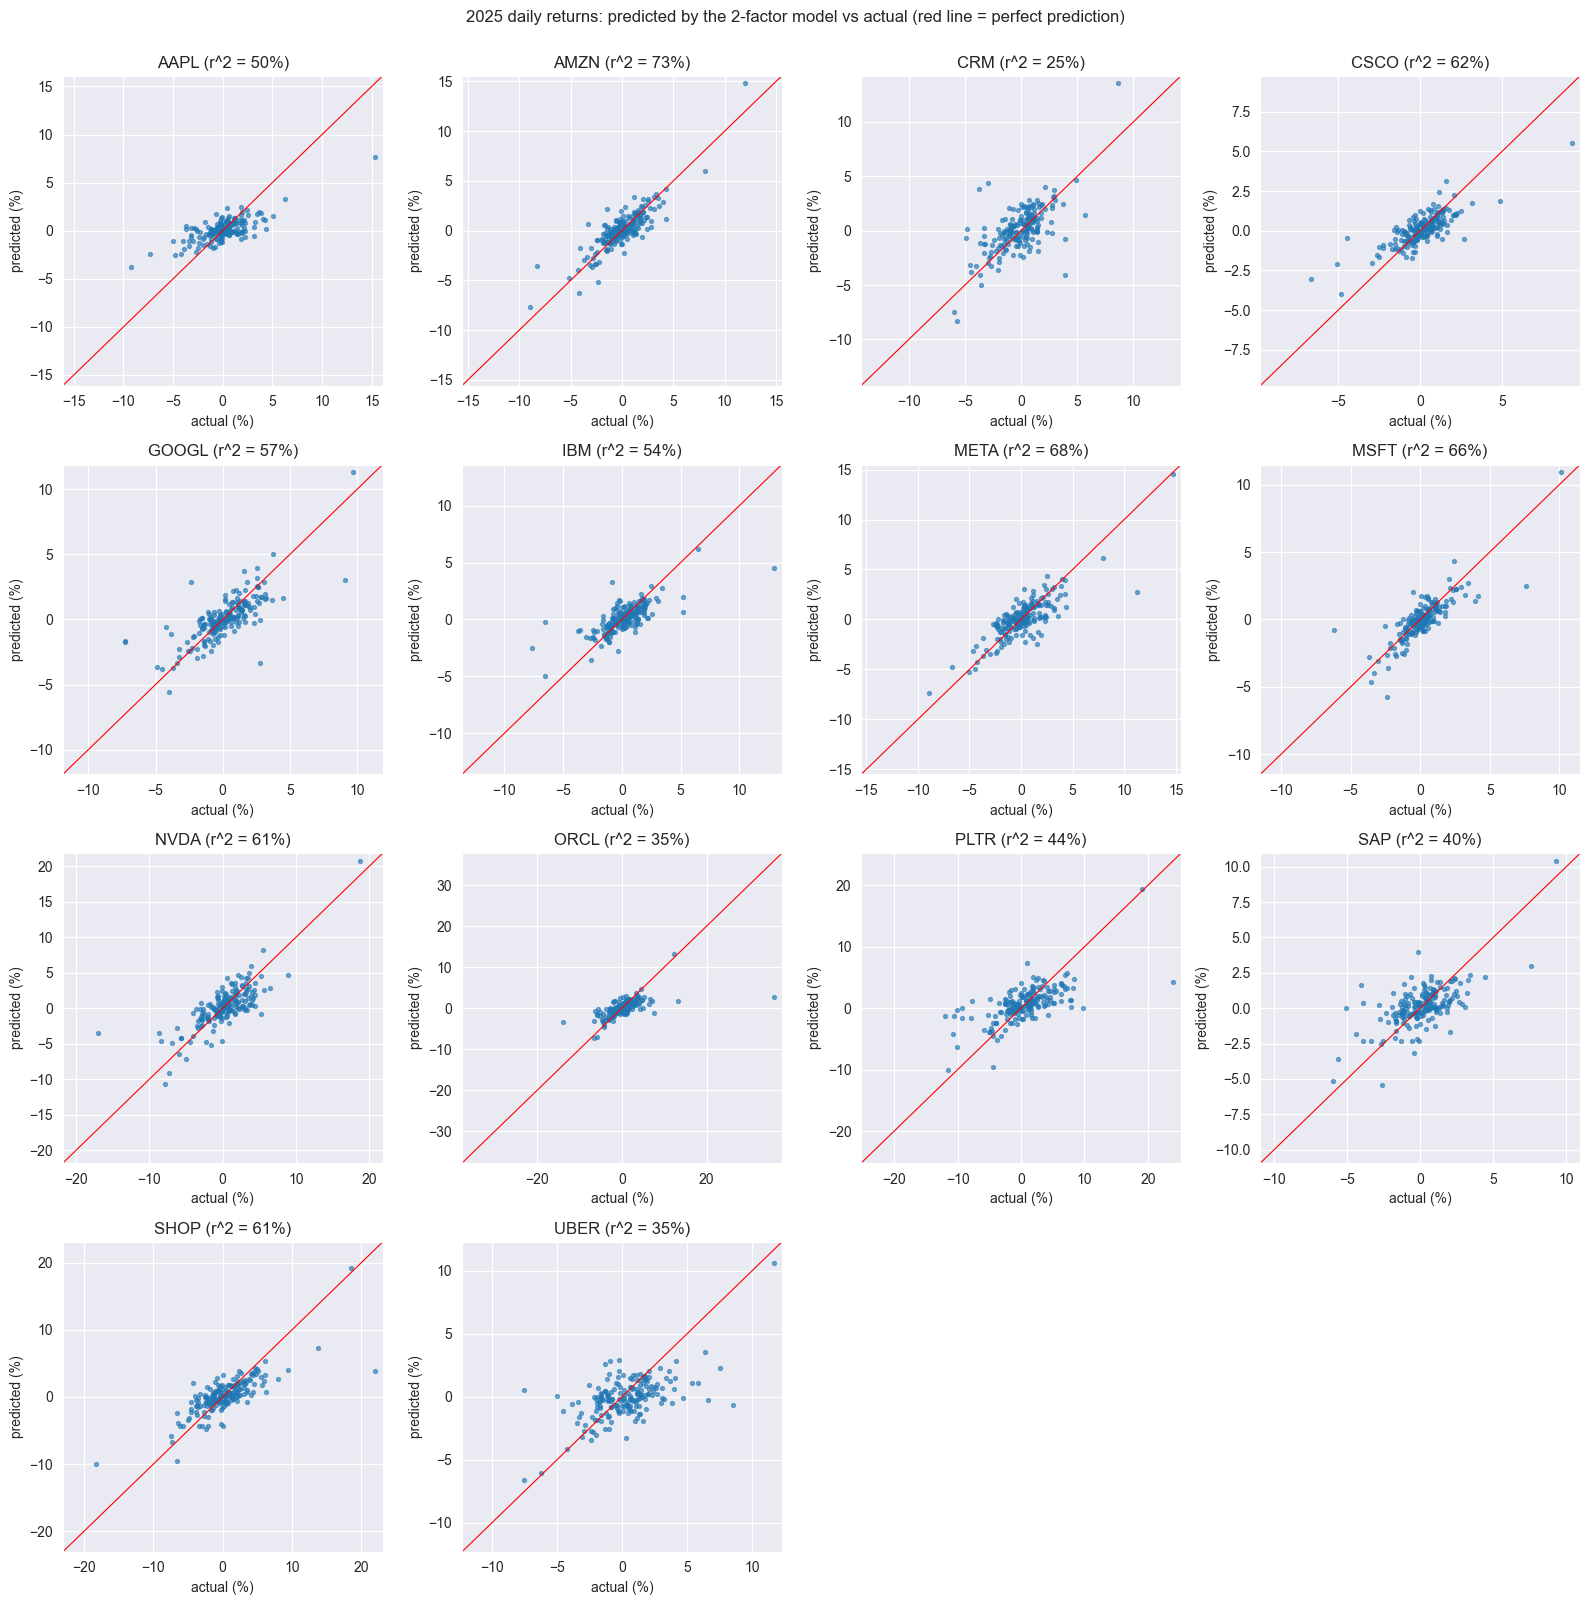

In [31]:
# Predicted vs Actual, 1 scatter per stock

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for ax, n in zip(axes.flatten(), range(number_of_stocks)):
    actual_pct = 100 * actual_returns_test[:, n]
    predicted_pct = 100 * predicted_returns_test[:,n]

    ax.scatter(actual_pct, predicted_pct, s=8, alpha=0.6)

    # same scale on both axes, plus the 45-degree line where predicted = actual
    limit = 1.05 * max(np.abs(actual_pct).max(), np.abs(predicted_pct).max())
    ax.plot([-limit, limit], [-limit, limit], color='red', linewidth=0.8)
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), title=f'{stock_names[n]} (r^2 = {100 * r_squared_test[n]:.0f}%)',
           xlabel='actual (%)', ylabel='predicted (%)')

# hide the 2 unused panels
for ax in axes.flatten()[number_of_stocks:]:
    ax.axis('off')

plt.suptitle('2025 daily returns: predicted by the 2-factor model vs actual (red line = perfect prediction)', y=1.0)
plt.tight_layout()
plt.show()

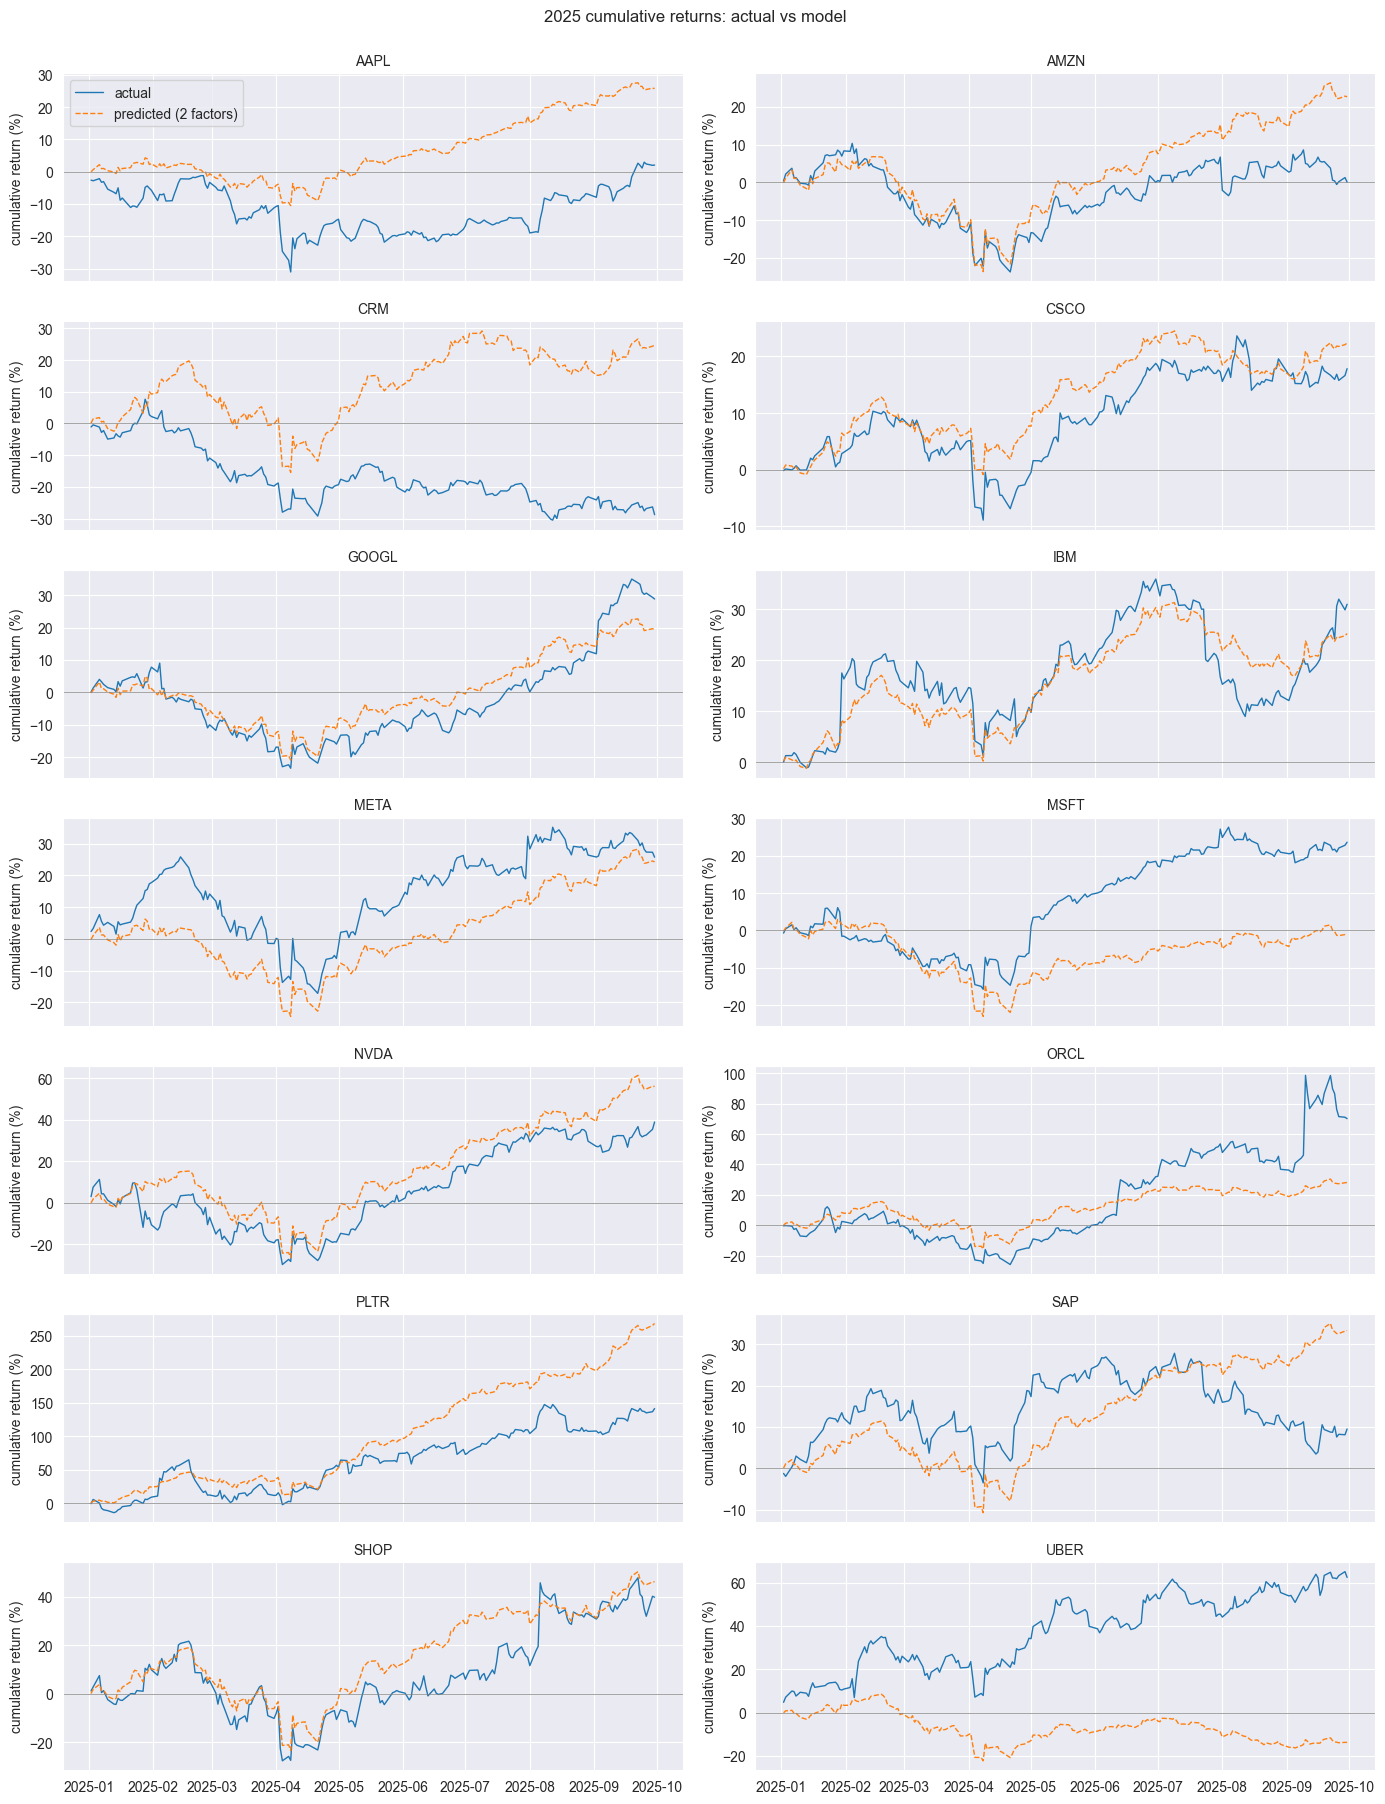

In [32]:
# Tracking over time (Cumulative returns 2025)

# Compound the daily returns to see whether the model tracks each stock's path through 2025
cumulative_actual = (1 + testing_returns).cumprod() - 1
cumulative_predicted = (1 + predicted_test).cumprod() - 1

fig, axes = plt.subplots(7, 2, figsize=(14, 18), sharex=True)
for ax, ticker in zip(axes.flatten(), stock_names):
    ax.plot(cumulative_actual.index, 100 * cumulative_actual[ticker], label='actual', linewidth=1)
    ax.plot(cumulative_predicted.index, 100 * cumulative_predicted[ticker], label='predicted (2 factors)',
            linestyle='--', linewidth=1)
    ax.axhline(0, color='grey', linewidth=0.5)
    ax.set_title(ticker, fontsize=10)
    ax.set_ylabel('cumulative return (%)')
axes[0, 0].legend()
plt.suptitle('2025 cumulative returns: actual vs model', y=1.0)
plt.tight_layout()
plt.show()

My choices Explained:

-